# **Build Your Own GPT Model**

`Alex E. Sanchez`

## Imports

In [ ]:
!pip install -U flax jax jaxlib optax orbax-checkpoint

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 533.9/533.9 kB 9.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 24.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 MB 52.2 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 62.7 MB/s  0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: jaxlib
    Found existing installation: jaxlib 0.11.1
    Uninstalling jaxlib-0.11.1:
      Successfully uninstalled jaxlib-0.11.1
  Attempting uninstall: jax
    Found existing installation: jax 0.11.1
    Uninstalling jax-0.11.1:
      Successfully uninstalled jax-0.11.1
  Attempting uninstall: gcsfs
    Found existing installation: gcsfs 2025.12.0
    Uninstalling gcsfs-2025.12.0:
      Successfully uninstalled gcsfs-2025.12.0
  Attempting uninstall: orbax-checkpoint
    Found existing installation: orb

In [ ]:
!pip install -qqq jaxtyping beartype wandb

In [ ]:
import jax
import jax.numpy as jnp
import flax.nnx as nnx
import optax
import orbax
import numpy as np
import orbax.checkpoint as ocp
from datasets import load_dataset
from dataclasses import dataclass
from jaxtyping import Float, Integer, jaxtyped, Array
from beartype import beartype
from transformers import GPT2TokenizerFast
from einops import rearrange
from tqdm.autonotebook import tqdm

/usr/local/lib/python3.13/dist-packages/jaxlib/plugin_support.py:99: RuntimeWarning: JAX plugin jax_cuda13_plugin version 0.11.1 is installed, but it is not compatible with the installed jaxlib version 0.12.0.1, so it will not be used.
  warnings.warn(


## Downloading our Dataset & Tokenizer

In [ ]:
%pip -q install -U datasets transformers langdetect

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:

from datasets import load_dataset
from transformers import GPT2TokenizerFast

import hashlib
import numpy as np
from pathlib import Path
from itertools import chain
from tqdm.auto import tqdm

dataset = load_dataset(
    "andrewelawrence/writingPrompts-merged",
    split="train"
)

tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")

print(f"Stories: {len(dataset):,}")
print(f"Vocabulary: {len(tokenizer):,}")
print(dataset[0]["story"][:500])


README.md:   0%|          | 0.00/736 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Stories: 303,358
Vocabulary: 50,257
The wet marble floor pressed on his cheek like a thousand hands slapping his face frozen in time. Smattering piss of rain ignored his indignant mumblings. His eyes fluttered. Pins and needs ran from finger to shoulder as he pushed back against the floor, contorting his aching body into a cross legged position. Last night was bad. He gathered that. His routine dullness of though crept inwards from the edges of his mind toward the black mist that veiled his most recent memories. He struggled to re


In [ ]:

def is_validation(prompt: str) -> bool:
    # Stable 5% split, grouped by writing prompt.
    prompt = " ".join(prompt.lower().split())
    digest = hashlib.md5(prompt.encode()).digest()
    return int.from_bytes(digest, "big") % 20 == 0


train_idx, val_idx = [], []

for i, prompt in enumerate(dataset["prompt"]):
    if is_validation(prompt):
        val_idx.append(i)
    else:
        train_idx.append(i)

train_ds = dataset.select(train_idx)
val_ds = dataset.select(val_idx)

print(f"Training stories:   {len(train_ds):,}")
print(f"Validation stories: {len(val_ds):,}")


Training stories:   288,885
Validation stories: 14,473


In [ ]:

DATA_DIR = Path("guildgpt_data")
DATA_DIR.mkdir(exist_ok=True)

EOS = tokenizer.eos_token_id

def tokenize_split(dataset, filename, batch_size=128):
    path = DATA_DIR / filename

    if not path.exists():
        with open(path, "wb") as f:
            for start in tqdm(
                range(0, len(dataset), batch_size),
                desc=f"Tokenizing {filename}"
            ):
                stories = dataset[
                    start:start + batch_size
                ]["story"]

                encoded = tokenizer(
                    stories,
                    add_special_tokens=False,
                    truncation=False
                )["input_ids"]

                # EOS separates individual stories.
                tokens = list(chain.from_iterable(
                    ids + [EOS] for ids in encoded if ids
                ))

                np.asarray(tokens, dtype=np.uint16).tofile(f)

    return np.memmap(path, dtype=np.uint16, mode="r")


train_tokens = tokenize_split(train_ds, "train.bin")
val_tokens = tokenize_split(val_ds, "val.bin")

print(f"Training tokens:   {len(train_tokens):,}")
print(f"Validation tokens: {len(val_tokens):,}")


Tokenizing train.bin:   0%|          | 0/2257 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1293 > 1024). Running this sequence through the model will result in indexing errors


Tokenizing val.bin:   0%|          | 0/114 [00:00<?, ?it/s]

Training tokens:   216,912,612
Validation tokens: 10,968,537


In [ ]:

def sample_batch(tokens, batch_size, seq_len, step, seed=42):
    rng = np.random.default_rng(seed + step)

    starts = rng.integers(
        0, len(tokens) - seq_len, size=batch_size
    )

    indices = starts[:, None] + np.arange(seq_len + 1)
    batch = tokens[indices]

    return jnp.asarray(batch, dtype=jnp.int32)


batch = sample_batch(
    train_tokens,
    batch_size=2,
    seq_len=1024,
    step=0
)

print(batch.shape)  # (2, 1025)


ERROR:jax._src.xla_bridge:Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 520, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda13/__init__.py", line 398, in initialize
    triton.register_compilation_handler(
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: module 'jax._src.lib.triton' has no attribute 'register_compilation_handler'


(2, 1025)


In [ ]:

import numpy as np
import pandas as pd
import re
import ast
import hashlib

from tqdm.auto import tqdm
from collections import Counter
from datasets import load_dataset
from transformers import GPT2TokenizerFast

tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")

dataset = load_dataset(
    "stevez80/Sci-Fi-Books-gutenberg",
    split="train"
)

print(dataset)
print(dataset.column_names)

README.md:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

sci-fi-books.csv: reconstructing file:   0%|          |  0.00B /  482MB            

sci-fi-books.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3354 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'title', 'author', 'text'],
    num_rows: 3354
})
['id', 'title', 'author', 'text']


In [ ]:
for book in dataset.select(range(5)):
    print(f"{book['title']} - {book['author']}")
    print(repr(book['text'][:150]))
    print('\n')

'Frankenstein; Or, The Modern Prometheus' - 'Shelley, Mary Wollstonecraft'
"b'\\xef\\xbb\\xbfThe Project Gutenberg eBook of Frankenstein; Or, The Modern Prometheus\\r\\n    \\r\\nThis ebook is for the use of anyone anywhere in the Un"


'The Strange Case of Dr. Jekyll and Mr. Hyde' - 'Stevenson, Robert Louis'
"b'\\xef\\xbb\\xbfThe Project Gutenberg eBook of The Strange Case of Dr. Jekyll and Mr. Hyde\\r\\n    \\r\\nThis ebook is for the use of anyone anywhere in th"


'Frankenstein; Or, The Modern Prometheus' - 'Shelley, Mary Wollstonecraft'
"b'\\xef\\xbb\\xbfThe Project Gutenberg eBook of Frankenstein; Or, The Modern Prometheus\\r\\n    \\r\\nThis ebook is for the use of anyone anywhere in the Un"


'Frankenstein; Or, The Modern Prometheus' - 'Shelley, Mary Wollstonecraft'
"b'\\xef\\xbb\\xbfThe Project Gutenberg eBook of Frankenstein; Or, The Modern Prometheus\\r\\n    \\r\\nThis ebook is for the use of anyone anywhere in the Un"


'The War of the Worlds' - 'Wells, H. G. (Herbert Geor

In [ ]:
def decode_text(text):
    if not isinstance(text, str):
        return ""

    if text.startswith(("b'", 'b"')):
        try:
            text = ast.literal_eval(text).decode("utf-8-sig", errors="replace")
        except (ValueError, SyntaxError, UnicodeError):
            pass

    return text.lstrip("\ufeff")


def clean_text(text):
    text = decode_text(text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")

    # Remove Gutenberg boilerplate where standard markers exist
    start = re.search(
        r"(?im)^\s*\*{3}\s*START OF (?:THE )?PROJECT GUTENBERG EBOOK[^\n]*",
        text
    )
    end = re.search(
        r"(?im)^\s*\*{3}\s*END OF (?:THE )?PROJECT GUTENBERG EBOOK[^\n]*",
        text
    )

    if start:
        text = text[start.end():]

    if end:
        # Search again because text may have been sliced
        end = re.search(
            r"(?im)^\s*\*{3}\s*END OF (?:THE )?PROJECT GUTENBERG EBOOK[^\n]*",
            text
        )
        if end:
            text = text[:end.start()]

    text = re.sub(r"\n{4,}", "\n\n", text)

    return text.strip()

In [ ]:

from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = 42

def normalize_name(text):
    return re.sub(r"\W+", " ", str(text).casefold()).strip()


def detect_language(text):
    try:
        return detect(text[:5000])
    except LangDetectException:
        return "unknown"


records = []

for book in tqdm(dataset, desc="Auditing books"):
    raw_text = decode_text(book["text"])
    text = clean_text(book["text"])

    # Count actual GPT-2 tokens
    raw_tokens = len(tokenizer.encode(raw_text, add_special_tokens=False))
    clean_tokens = len(tokenizer.encode(text, add_special_tokens=False))

    # Normalized content hash for exact/near-format duplicates
    normalized = re.sub(r"\s+", " ", text).strip()
    content_hash = hashlib.sha256(normalized.encode("utf-8")).hexdigest()

    records.append({
        "id": book["id"],
        "title": book["title"],
        "author": book["author"],
        "work_key": (
            normalize_name(book["author"]),
            normalize_name(book["title"])
        ),
        "language": detect_language(text),
        "characters": len(text),
        "raw_tokens": raw_tokens,
        "tokens": clean_tokens,
        "content_hash": content_hash,
        "has_start_marker": bool(re.search(
            r"\*{3}\s*START OF (?:THE )?PROJECT GUTENBERG EBOOK",
            raw_text, re.IGNORECASE
        )),
        "has_end_marker": bool(re.search(
            r"\*{3}\s*END OF (?:THE )?PROJECT GUTENBERG EBOOK",
            raw_text, re.IGNORECASE
        ))
    })

df = pd.DataFrame(records)

print("Dataset audit completed!")


Auditing books:   0%|          | 0/3354 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (114252 > 1024). Running this sequence through the model will result in indexing errors


Dataset audit completed!


In [ ]:

print("=" * 55)
print("GUILDGPT — SCIENCE FICTION DATASET REPORT")
print("=" * 55)

print(f"Total entries:           {len(df):,}")
print(f"Unique titles/authors:   {df['work_key'].nunique():,}")
print(f"Unique content hashes:   {df['content_hash'].nunique():,}")
print()

print(f"Raw tokens:              {df['raw_tokens'].sum():,}")
print(f"Cleaned tokens:          {df['tokens'].sum():,}")
print(f"Average tokens/book:     {df['tokens'].mean():,.0f}")
print(f"Median tokens/book:      {df['tokens'].median():,.0f}")
print()

print("Token length distribution:")
print(df["tokens"].describe(percentiles=[.10, .25, .50, .75, .90, .95]).round())
print()

print("Language distribution:")
print(df["language"].value_counts().to_string())
print()

print("Missing Gutenberg markers:")
print(f"Start: {(~df['has_start_marker']).sum():,}")
print(f"End:   {(~df['has_end_marker']).sum():,}")


GUILDGPT — SCIENCE FICTION DATASET REPORT
Total entries:           3,354
Unique titles/authors:   3,298
Unique content hashes:   3,354

Raw tokens:              128,445,938
Cleaned tokens:          103,860,830
Average tokens/book:     30,966
Median tokens/book:      11,206

Token length distribution:
count       3354.0
mean       30966.0
std        64786.0
min            0.0
10%         4005.0
25%         6643.0
50%        11206.0
75%        28440.0
90%        90309.0
95%       126563.0
max      2687963.0
Name: tokens, dtype: float64

Language distribution:
language
en         3218
fr           42
fi           30
de           20
nl           14
hu            8
es            5
pt            4
da            2
it            2
sv            2
cs            1
el            1
ja            1
bn            1
sl            1
unknown       1
no            1

Missing Gutenberg markers:
Start: 36
End:   36


In [ ]:

display(
    df.nlargest(10, "tokens")[
        ["title", "author", "language", "tokens"]
    ]
)

display(
    df.nsmallest(10, "tokens")[
        ["title", "author", "language", "tokens"]
    ]
)


,title,author,language,tokens
830,'In the Clutch of the War-God',"'Hastings, Milo'",bn,2687963
57,"""L'île mystérieuse""","'Verne, Jules'",fr,466454
1673,'Yhdenvertaisuus',"'Bellamy, Edward'",fi,409289
465,'Les naufragés du Jonathan',"'Verne, Jules'",fr,345306
69,'Vingt mille lieues sous les mers',"'Verne, Jules'",fr,343844
79,'Vingt mille Lieues Sous Les Mers — Complete',"'Verne, Jules'",fr,337714
427,"'Λουκιανός - Άπαντα, Τόμος Τρίτος'","'Lucian, of Samosata'",el,302903
1085,"""Aventures extraordinaires d'un savant russe; ...","'Graffigny, H. de (Henry)'",fr,285818
26,'The Mysterious Island',"'Verne, Jules'",en,284571
531,'Darkness and Dawn',"'England, George Allan'",en,283538


,title,author,language,tokens
725,'Micromégas','Voltaire',unknown,0
2888,"'Watch (First 25,000 words)'","'Sawyer, Robert J.'",en,42
2659,"'Wake (First 25,000 words)'","'Sawyer, Robert J.'",en,46
1349,'Oomphel in the Sky',"'Piper, H. Beam'",en,496
2792,'The Hands',"'Sternbach, Richard A.'",en,502
2089,'Omnilingual',"'Piper, H. Beam'",en,503
713,'Voodoo Planet',"'Norton, Andre'",en,537
185,'Five Sci-Fi Short Stories',"'Piper, H. Beam'",en,544
641,'Anthem',"'Rand, Ayn'",en,581
269,'Plague Ship',"'Norton, Andre'",en,712


In [ ]:

# Start with English entries of reasonable length
usable = df[
    (df["language"] == "en") &
    (df["tokens"] >= 500)
].copy()

# Remove duplicate contents
usable = usable.drop_duplicates(
    subset="content_hash"
)

# Keep the longest edition of each author/title
usable = (
    usable.sort_values("tokens", ascending=False)
          .drop_duplicates(subset="work_key")
          .reset_index(drop=True)
)

total_tokens = int(usable["tokens"].sum())

print("=" * 55)
print("GUILDGPT — USABLE CORPUS")
print("=" * 55)
print(f"Usable books:        {len(usable):,}")
print(f"Usable GPT-2 tokens: {total_tokens:,}")
print(f"Average tokens/book: {usable['tokens'].mean():,.0f}")
print(f"Median tokens/book:  {usable['tokens'].median():,.0f}")
print()

print("Token distribution:")
print(usable["tokens"].describe(percentiles=[.10, .25, .50, .75, .90]).round())

usable.to_csv("guildgpt_dataset_audit.csv", index=False)


GUILDGPT — USABLE CORPUS
Usable books:        3,162
Usable GPT-2 tokens: 80,391,586
Average tokens/book: 25,424
Median tokens/book:  10,643

Token distribution:
count      3162.0
mean      25424.0
std       35995.0
min         502.0
10%        3946.0
25%        6587.0
50%       10643.0
75%       24453.0
90%       77160.0
max      284571.0
Name: tokens, dtype: float64


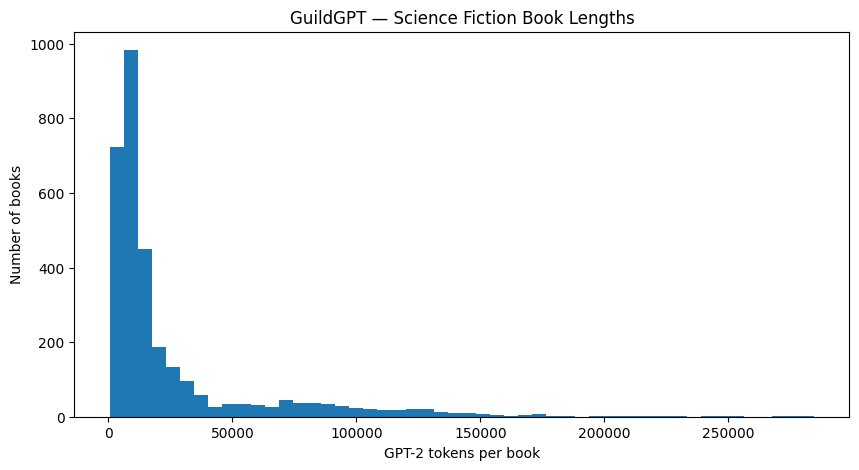

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(usable["tokens"], bins=50)

plt.xlabel("GPT-2 tokens per book")
plt.ylabel("Number of books")
plt.title("GuildGPT — Science Fiction Book Lengths")

plt.show()


In [ ]:

largest_10_share = usable.nlargest(10, "tokens")["tokens"].sum() / total_tokens

print(f"Top 10 books contain {largest_10_share:.1%} of all tokens")
print(f"Tokens per character: {total_tokens / usable['characters'].sum():.3f}")


Top 10 books contain 3.2% of all tokens
Tokens per character: 0.263


## GPT (x_param) Configuration

In [ ]:
@dataclass(frozen=True)
class GuildGPTConfig:
    max_seq_len: int = 64
    vocab_size: int = 50257

    n_layers: int = 2
    n_heads: int = 4
    hidden_size: int = 128
    mlp_hidden_size: int = 512


config = GuildGPTConfig()


## **Neural Network Modules**

### Multi-Head Self-Attention (MHSA)

In [ ]:
class MultiHeadSelfAttention(nnx.Module):
    def __init__(self, config: GuildGPTConfig, rngs: nnx.Rngs):
        self.n_heads = config.n_heads
        self.head_size = config.hidden_size // config.n_heads
        self.output_size = config.hidden_size
        self.hidden_size = config.hidden_size

        assert self.hidden_size % self.n_heads == 0

        self.Wq = nnx.Linear(self.hidden_size, self.hidden_size, use_bias=True, rngs=rngs)
        self.Wk = nnx.Linear(self.hidden_size, self.hidden_size, use_bias=True, rngs=rngs)
        self.Wv = nnx.Linear(self.hidden_size, self.hidden_size, use_bias=True, rngs=rngs)
        self.Wo = nnx.Linear(self.hidden_size, self.hidden_size, use_bias=True, rngs=rngs)

    @jaxtyped(typechecker=beartype)
    def __call__(self, x: Float[Array, 'b n h']) -> Float[Array, 'b n h']:
        q, k, v = self.Wq(x), self.Wk(x), self.Wv(x)

        # Split into heads: (b, n, h) -> (b, heads, n, head_size)
        def mha_reshape(tensor):
            return rearrange(tensor, 'b n (heads d) -> b heads n d', heads=self.n_heads)
        Q, K, V = map(mha_reshape, (q, k, v))

        # Scaled Dot Product Attention
        # For QKᵀ we want (n, head_size) @ (head_size, n)
        scale = self.head_size ** -0.5
        attention_weights = jnp.einsum('b h i d, b h j d -> b h i j', Q, K)
        attention_weights = attention_weights * scale

        # Causal mask:
        #     k0  k1  k2  k3
        # q0 [■   □   □   □ ]
        # q1 [■   ■   □   □ ]
        # q2 [■   ■   ■   □ ]
        # q3 [■   ■   ■   ■ ]
        _, seq_len, _ = x.shape
        causal_mask = jnp.tril(jnp.ones((seq_len, seq_len), dtype=jnp.bool_))

        # All □ become -∞
        attention_weights = jnp.where(causal_mask, attention_weights, float('-inf'))
        attention_weights = nnx.softmax(attention_weights, axis=-1)

        out = jnp.einsum('b h i j, b h j d -> b h i d', attention_weights, V)

        # Merge heads: (b, heads, n, head_size) -> (b, n, h)
        out = rearrange(out, 'b heads n d -> b n (heads d)')

        return self.Wo(out)

### Multi-Layer Perceptron (MLP)

In [ ]:
class MultiLayerPerceptron(nnx.Module):
    def __init__(self, config: GuildGPTConfig, rngs: nnx.Rngs):
        self.fc1 = nnx.Linear(config.hidden_size, config.mlp_hidden_size, use_bias=True, rngs=rngs)
        self.fc2 = nnx.Linear(config.mlp_hidden_size, config.hidden_size, use_bias=True, rngs=rngs)

    @jaxtyped(typechecker=beartype)
    def __call__(self, x: Float[Array, 'b n h']) -> Float[Array, 'b n h']:
        x = self.fc1(x)
        x = jax.nn.gelu(x)
        x = self.fc2(x)
        return x

### Transformer Layers

In [ ]:
class TransformerLayer(nnx.Module):
    def __init__(self, config: GuildGPTConfig, rngs: nnx.Rngs):
        self.mhsa = MultiHeadSelfAttention(config, rngs=rngs)
        self.mlp = MultiLayerPerceptron(config, rngs=rngs)
        self.ln1 = nnx.LayerNorm(config.hidden_size, rngs=rngs)
        self.ln2 = nnx.LayerNorm(config.hidden_size, rngs=rngs)

    @jaxtyped(typechecker=beartype)
    def __call__(self, x: Float[Array, 'b n h']) -> Float[Array, 'b n h']:
        x = x + self.mhsa(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

## **Full Model!!!**

In [ ]:
class GuildGPT(nnx.Module):
    def __init__(self, config: GuildGPTConfig, rngs: nnx.Rngs):
        self.config = config
        self.wte = nnx.Embed(config.vocab_size, config.hidden_size, rngs=rngs)
        self.wpe = nnx.Embed(config.max_seq_len, config.hidden_size, rngs=rngs)
        self.layers = nnx.List([TransformerLayer(config, rngs) for _ in range(config.n_layers)])
        self.ln_f = nnx.LayerNorm(config.hidden_size, rngs=rngs)

    @jaxtyped(typechecker=beartype)
    def __call__(self, input_ids: Integer[Array, 'b n']) -> Float[Array, 'b n v']:
        _, seq_len = input_ids.shape

        positions = jnp.arange(seq_len)

        # Token Embeddings + Positional Embeddings
        x = self.wte(input_ids) + self.wpe(positions)

        # Pass the hidden state through our layers
        for layer in self.layers:
            x = layer(x)

        x = self.ln_f(x)

        # Weight tying!
        logits = self.wte.attend(x)

        return logits

### Generating a Sentence

In [ ]:
def generate(model: GuildGPT, prompt: str, max_new_tokens: int = 100, temperature: float = 0.8, top_k: int = 50) -> str:
    input_ids = jnp.array(tokenizer.encode(prompt))[None, :]
    key = jax.random.PRNGKey(42)

    for _ in range(max_new_tokens):
        logits = model(input_ids[:, -model.config.max_seq_len:])
        logits = logits[:, -1, :] / temperature

        # Top-k sampling
        top_logits, top_ids = jax.lax.top_k(logits, top_k)

        key, subkey = jax.random.split(key)
        sample = jax.random.categorical(subkey, top_logits, axis=-1)

        next_token = jnp.take_along_axis(
            top_ids, sample[:, None], axis=-1
        )

        if int(next_token[0, 0]) == tokenizer.eos_token_id:
            break

        input_ids = jnp.concatenate([input_ids, next_token], axis=1)

    return tokenizer.decode(
        np.asarray(input_ids[0]),
        skip_special_tokens=True
    )

### Our Current (Dumb) Model

In [ ]:
config = GuildGPTConfig()
dumb_model = GuildGPT(config, nnx.Rngs(42))
print(generate(dumb_model, "The quick brown fox"))

The quick brown foxMarvel Oracle MareRoom rivers cares writings BET Julius dou copperPickmp worship Bere phenomennation humour GI ind 152,'' neteri copper Rohing Brass balance RohingFalse clumsyCompl writings Roe writings unsuccessfully unsuccessfully ABE CoC thorough copper merge toggleify Television discernTi Rocksí worship copper distinctions Deadly toggleeming toilet CoC光 longing copper Noirulumorescenceaa boards detriment straight Statistical� ABE impe Czech................................ Array�Init� Pastor vitality copperph Brass trigger constituentsazines ask Meh ninjaazinesTop impe intrigue dives Hungarian impe Sue divesatmeal fungi


## Training

In [ ]:
def compute_loss(model: GuildGPT, input_ids: Integer[Array, 'b n']) -> Float[Array, '']:
    logits = model(input_ids[:, :-1])
    targets = input_ids[:, 1:]

    # Cross-Entropy
    loss = optax.softmax_cross_entropy_with_integer_labels(
        logits=logits.astype(jnp.float32),
        labels=targets
    )

    return loss.mean()

In [ ]:
@nnx.jit
def train_step(model: GuildGPT, optimizer: nnx.Optimizer, input_ids):
    loss, grads = nnx.value_and_grad(compute_loss)(model, input_ids)
    optimizer.update(model, grads)
    return loss

In [ ]:
@nnx.jit
def eval_step(model: GuildGPT, input_ids):
    return compute_loss(model, input_ids)

In [ ]:
STEPS = 150
BATCH_SIZE = 2
LOG_EVERY = 25
EVAL_EVERY = 50
SAVE_EVERY = 75

schedule = optax.warmup_cosine_decay_schedule(
    init_value=0.0,
    peak_value=3e-4,
    warmup_steps=10,
    decay_steps=STEPS,
    end_value=3e-5
)

tx = optax.chain(
    optax.clip_by_global_norm(1.0),
    optax.adamw(learning_rate=schedule, weight_decay=0.1),
)

In [ ]:

config = GuildGPTConfig(
    max_seq_len=1024,
    vocab_size=len(tokenizer),
    n_layers=12,
    n_heads=12,
    hidden_size=768
)

model = GuildGPT(config, rngs=nnx.Rngs(42))


In [ ]:
model = GuildGPT(config, rngs=nnx.Rngs(42))
optimizer = nnx.Optimizer(model, tx, wrt=nnx.Param)

total_params = sum(x.size for x in jax.tree.leaves(nnx.state(model)))
print(f"Total parameters: {total_params:,}")

Total parameters: 6,837,888


In [ ]:

import optax

STEPS = 2_500           # Initial test, not final training
BATCH_SIZE = 2
SEQ_LEN = config.max_seq_len

schedule = optax.warmup_cosine_decay_schedule(
    init_value=0.0,
    peak_value=3e-4,
    warmup_steps=10,
    decay_steps=STEPS,
    end_value=3e-5
)

optimizer = nnx.Optimizer(
    model,
    optax.chain(
        optax.clip_by_global_norm(1.0),
        optax.adamw(schedule, weight_decay=0.1)
    ),
    wrt=nnx.Param
)

for step in tqdm(range(STEPS), desc="Training GuildGPT"):
    batch = sample_batch(
        train_tokens, BATCH_SIZE, SEQ_LEN, step
    )

    loss = train_step(model, optimizer, batch)

    if (step + 1) % 25 == 0:
        val_batch = sample_batch(
            val_tokens, BATCH_SIZE, SEQ_LEN,
            step=step, seed=9999
        )

        val_loss = eval_step(model, val_batch)

        print(
            f"Step {step + 1} | "
            f"Train: {float(loss):.4f} | "
            f"Val: {float(val_loss):.4f}"
        )


Training GuildGPT:   0%|          | 0/100 [00:00<?, ?it/s]

Step 25 | Train: 6.6936 | Val: 7.0636
Step 50 | Train: 7.1280 | Val: 6.4946
Step 75 | Train: 6.3735 | Val: 6.2623
Step 100 | Train: 6.4371 | Val: 6.3472


In [ ]:

def evaluate(model, tokens, seq_len=1024, n_batches=32):
    losses = []

    for i in range(n_batches):
        batch = sample_batch(
            tokens,
            batch_size=2,
            seq_len=seq_len,
            step=i,
            seed=12345
        )

        loss = eval_step(model, batch)
        losses.append(float(loss))

    return np.mean(losses)


val_loss = evaluate(model, val_tokens)
print(f"Validation loss: {val_loss:.4f}")


Validation loss: 6.3507


In [ ]:

import time
import jax

# Warm up JIT compilation first.
batch = sample_batch(train_tokens, 2, 1024, step=101)
jax.block_until_ready(train_step(model, optimizer, batch))

start = time.perf_counter()

for step in range(102, 122):
    batch = sample_batch(train_tokens, 2, 1024, step)
    loss = train_step(model, optimizer, batch)

jax.block_until_ready(loss)
elapsed = time.perf_counter() - start

tokens_per_second = 20 * 2 * 1024 / elapsed

print(f"Tokens/sec: {tokens_per_second:,.0f}")
print(f"Seconds/step: {elapsed / 20:.2f}")


Tokens/sec: 5,529
Seconds/step: 0.37


In [ ]:

import jax
import jaxlib
import jax.numpy as jnp

print("JAX version:", jax.__version__)
print("JAXlib version:", jaxlib.__version__)
print("Backend:", jax.default_backend())
print("Devices:", jax.devices())

x = jnp.ones((10, 10))
print("Array device:", x.device)


JAX version: 0.12.0.1
JAXlib version: 0.12.0.1
Backend: gpu
Devices: [CudaDevice(id=0)]
Array device: cuda:0


In [ ]:
train_losses = []
val_losses = []

for step in tqdm(range(1, STEPS + 1), desc='Training'):
    loss = train_step(model, optimizer, train_batch)

    if step % LOG_EVERY == 0:
        train_loss = float(loss)
        train_losses.append(train_loss)

        print(f"Step {step} | Training Loss: {train_loss:.4f}")

In [ ]:
final_loss = float(eval_step(model, train_batch))

print(f"Final Loss:   {final_loss:.4f}")

print("Training sanity check passed!")

In [ ]:

from pathlib import Path

checkpoint_path = Path("guildgpt_smoke_ckpt").resolve()

checkpointer = ocp.StandardCheckpointer()

# Save model and optimizer
state = {
    "model": nnx.state(model),
    "optimizer": nnx.state(optimizer)
}

checkpointer.save(checkpoint_path, state, force=True)
checkpointer.wait_until_finished()

print(f"Checkpoint saved to {checkpoint_path}")


In [ ]:

# Create a fresh model
restored_model = GuildGPT(config, rngs=nnx.Rngs(123))
restored_optimizer = nnx.Optimizer(restored_model, tx, wrt=nnx.Param)

# Expected state structure
target = {
    "model": nnx.state(restored_model),
    "optimizer": nnx.state(restored_optimizer)
}

# Restore saved state
restored = checkpointer.restore(checkpoint_path, target)

nnx.update(restored_model, restored["model"])
nnx.update(restored_optimizer, restored["optimizer"])

# Check that the restored model produces the same loss
restored_loss = float(eval_step(restored_model, train_batch))

print(f"Original model loss: {final_loss:.6f}")
print(f"Restored model loss: {restored_loss:.6f}")

assert np.isclose(final_loss, restored_loss, atol=1e-5)

checkpointer.close()

print("Checkpoint restoration passed!")


## **Testing the Final Model**

In [ ]:

logits = model(train_batch[:, :-1])

print(f"Logits: {logits.shape}")
print(f"Expected: {(2, 64, config.vocab_size)}")

assert logits.shape == (2, 64, config.vocab_size)

initial_loss = float(eval_step(model, train_batch))
print(f"Initial loss: {initial_loss:.4f}")

assert np.isfinite(initial_loss)


In [ ]:

# Create a fresh model
restored_model = GuildGPT(config, rngs=nnx.Rngs(123))
restored_optimizer = nnx.Optimizer(restored_model, tx, wrt=nnx.Param)

# Expected state structure
target = {
    "model": nnx.state(restored_model),
    "optimizer": nnx.state(restored_optimizer)
}

# Restore saved state
restored = checkpointer.restore(checkpoint_path, target)

nnx.update(restored_model, restored["model"])
nnx.update(restored_optimizer, restored["optimizer"])

# Check that the restored model produces the same loss
restored_loss = float(eval_step(restored_model, train_batch))

print(f"Original model loss: {final_loss:.6f}")
print(f"Restored model loss: {restored_loss:.6f}")

assert np.isclose(final_loss, restored_loss, atol=1e-5)

checkpointer.close()

print("Checkpoint restoration passed!")


In [ ]:
# Generate from a prefix the model has encountered
prompt = tokenizer.decode(
    np.asarray(train_batch[0, :8]),
    skip_special_tokens=True
)

print(f"Prompt: {prompt}")
print()

output = generate(
    restored_model,
    prompt,
    max_new_tokens=40,
    temperature=0.8,
    top_k=20
)

print(output)

In [ ]:

import optax
from flax import nnx

STEPS = 5_000
BATCH_SIZE = 2
SEQ_LEN = 1024

# Fresh model and optimizer for the pilot.
model = GuildGPT(config, rngs=nnx.Rngs(42))

schedule = optax.warmup_cosine_decay_schedule(
    init_value=0.0,
    peak_value=3e-4,
    warmup_steps=200,
    decay_steps=STEPS,
    end_value=3e-5,
)

optimizer = nnx.Optimizer(
    model,
    optax.chain(
        optax.clip_by_global_norm(1.0),
        optax.adamw(schedule, weight_decay=0.1),
    ),
    wrt=nnx.Param,
)


In [ ]:

from tqdm.auto import tqdm
import jax
import time

start = time.perf_counter()

for step in tqdm(range(STEPS)):
    batch = sample_batch(
        train_tokens,
        batch_size=BATCH_SIZE,
        seq_len=SEQ_LEN,
        step=step,
    )

    loss = train_step(model, optimizer, batch)

    if (step + 1) % 500 == 0:
        jax.block_until_ready(loss)

        val_loss = evaluate(
            model,
            val_tokens,
            seq_len=SEQ_LEN,
            n_batches=16,
        )

        elapsed = time.perf_counter() - start

        print(
            f"Step {step + 1:5d} | "
            f"Train: {float(loss):.4f} | "
            f"Val: {val_loss:.4f} | "
            f"Elapsed: {elapsed / 60:.1f} min"
        )


  0%|          | 0/5000 [00:00<?, ?it/s]

Step   500 | Train: 5.7811 | Val: 5.4703 | Elapsed: 3.6 min
Step  1000 | Train: 4.9832 | Val: 5.2467 | Elapsed: 7.4 min
Step  1500 | Train: 5.2661 | Val: 5.1418 | Elapsed: 11.3 min
Step  2000 | Train: 5.0547 | Val: 5.0588 | Elapsed: 15.2 min
Step  2500 | Train: 4.9128 | Val: 4.9818 | Elapsed: 19.1 min
Step  3000 | Train: 5.2729 | Val: 4.9263 | Elapsed: 23.0 min
Step  3500 | Train: 4.9792 | Val: 4.8591 | Elapsed: 26.8 min
Step  4000 | Train: 5.1304 | Val: 4.8030 | Elapsed: 30.7 min
Step  4500 | Train: 5.1396 | Val: 4.7651 | Elapsed: 34.6 min
Step  5000 | Train: 4.7920 | Val: 4.7338 | Elapsed: 38.6 min


In [ ]:
print(generate(model, "The quick brown fox"))

In [ ]:
print(generate(model, "The robot had been programmed never to lie. Today, it broke that rule."))

The robot had been programmed never to lie. Today, it broke that rule. 
 
 `` Come here,'' he said his voice said to a hand, `` A man said, please you do n't take it's not in the guy.'' 
 
 `` I'd been on, the floor.'' 
 `` I'm going to tell,'' the wall. I'm getting the front door and turned to the man. `` What do not a question to get a big. What are you do it?'' 
 
 `` I do you doing?
